# Training data exploration

Use the persisted 80/20 stratified split for every experiment. Explore training rows only. The content fingerprint `_row_id` records membership; it is never a predictor. This random split does not establish future-loan or unseen-borrower performance.

`loan_status = 1` is class 1; its business meaning is undocumented.

In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import display
from ml_gearbox import audit as ga

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
RAW_PATH = PROJECT_ROOT / "data/raw/data.csv"
assert RAW_PATH.is_file(), f"Missing raw data: {RAW_PATH}"
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from ml_gearbox import eda as ge
from src.data import get_or_create_split
from src.schema import NUMERIC_COLUMNS, TARGET

In [2]:
df = pd.read_csv(RAW_PATH)
split = get_or_create_split(df, path=PROJECT_ROOT / "data/processed/split.parquet")
train = split["train"]

numeric_columns = list(NUMERIC_COLUMNS)
display(ge.target_distribution(train, TARGET))
display(ga.numeric_profile(train[numeric_columns]))

,count,percentage
loan_status,,
0,321959,77.587212
1,93005,22.412788


,count,mean,std,min,25%,50%,75%,max,median,skew,n_unique
annual_inc,414964.0,78906.693146,73774.129071,0.00,48000.0000,66000.000,95000.00,9300000.00,66000.000,39.795272,26678
dti,414672.0,18.793956,14.812837,-1.00,11.8300,17.820,24.57,999.00,17.820,31.081790,6718
pub_rec,414964.0,0.244990,0.631790,0.00,0.0000,0.000,0.00,61.00,0.000,9.419092,29
delinq_2yrs,414964.0,0.328086,0.909476,0.00,0.0000,0.000,0.00,29.00,0.000,5.693265,26
pub_rec_bankruptcies,414964.0,0.154852,0.401105,0.00,0.0000,0.000,0.00,9.00,0.000,3.079687,10
inq_last_6mths,414963.0,0.587356,0.870168,0.00,0.0000,0.000,1.00,5.00,0.000,1.726268,6
mort_acc,414964.0,1.549761,1.848206,0.00,0.0000,1.000,3.00,51.00,1.000,1.624434,31
fico_range_low,414964.0,698.035131,33.570088,660.00,670.0000,690.000,715.00,845.00,690.000,1.236182,38
total_acc,414964.0,24.594206,12.234122,2.00,16.0000,23.000,31.00,176.00,23.000,1.059950,128
installment,414964.0,443.793244,281.830626,30.12,237.0675,368.855,596.68,1719.83,368.855,1.035305,47935


In [3]:
display(ga.missingness_report(train))
display(ge.zero_percentage(train, columns=numeric_columns))
display(ge.iqr_outlier_summary(train, columns=numeric_columns))

,feature,missing_count,percentage
0,emp_length,28727,6.922769
1,revol_util,336,0.080971
2,dti,292,0.070368
3,inq_last_6mths,1,0.000241


,feature,zero_pct
0,pub_rec_bankruptcies,85.635621
1,pub_rec,80.718086
2,delinq_2yrs,80.391311
3,inq_last_6mths,59.893870
4,mort_acc,40.822095
5,revol_util,0.706567
6,dti,0.086514
7,annual_inc,0.067476


,feature,q1,q3,iqr,lower_bound,upper_bound,outlier_count,outlier_pct
0,delinq_2yrs,0.0000,0.00,0.0000,0.00000,0.00000,81369,19.608689
1,pub_rec,0.0000,0.00,0.0000,0.00000,0.00000,80013,19.281914
2,pub_rec_bankruptcies,0.0000,0.00,0.0000,0.00000,0.00000,59607,14.364379
3,annual_inc,48000.0000,95000.00,47000.0000,-22500.00000,165500.00000,19489,4.696552
4,inq_last_6mths,0.0000,1.00,1.0000,-1.50000,2.50000,17019,4.101320
5,int_rate,9.4900,16.02,6.5300,-0.30500,25.81500,13506,3.254740
6,installment,237.0675,596.68,359.6125,-302.35125,1136.09875,12974,3.126536
7,fico_range_low,670.0000,715.00,45.0000,602.50000,782.50000,12064,2.907240
8,total_acc,16.0000,31.00,15.0000,-6.50000,53.50000,10423,2.511784
9,loan_amnt,7200.0000,20000.00,12800.0000,-12000.00000,39200.00000,5462,1.316259


IQR flags describe distribution tails. They do not establish invalid records, particularly for sparse counts and skewed income. Check units and source rules before clipping or removing observations.

In [4]:
correlations = ge.correlation_matrix(train, columns=numeric_columns)
display(ge.high_correlation_pairs(correlations, threshold=0.85))
display(ge.numeric_target_rate_by_quantile(train, "int_rate", TARGET, bins=8))
display(ge.categorical_target_rate(train, "term", TARGET))
display(ge.categorical_target_rate(train, "emp_length", TARGET))

,feature_1,feature_2,correlation
0,loan_amnt,installment,0.955663


,bin,count,positives,target_rate,target_rate_pct
0,"(5.308999999999999, 7.59]",52508,3109,0.059210,5.921003
1,"(7.59, 9.49]",51348,5911,0.115116,11.511646
2,"(9.49, 11.39]",53336,8215,0.154024,15.402355
3,"(11.39, 12.74]",57493,11334,0.197137,19.713704
4,"(12.74, 13.99]",47161,11683,0.247726,24.772588
5,"(13.99, 16.02]",54583,15304,0.280380,28.038034
6,"(16.02, 19.53]",47260,15773,0.333749,33.374947
7,"(19.53, 30.99]",51275,21676,0.422740,42.274013


,term,count,positives,target_rate,target_rate_pct
0,60 months,93229,31085,0.333426,33.342629
1,36 months,321735,61920,0.192457,19.245652


,emp_length,count,positives,target_rate,target_rate_pct
0,NaN,28727,8818,0.306959,30.695861
1,1 year,27969,6658,0.238049,23.804927
2,< 1 year,33713,7831,0.232284,23.228428
3,3 years,33623,7677,0.228326,22.832585
4,2 years,38320,8733,0.227897,22.789666
5,4 years,25022,5582,0.223084,22.308369
6,5 years,25468,5639,0.221415,22.141511
7,8 years,15840,3464,0.218687,21.868687
8,7 years,14243,3104,0.217932,21.793162
9,9 years,15102,3270,0.216528,21.652761


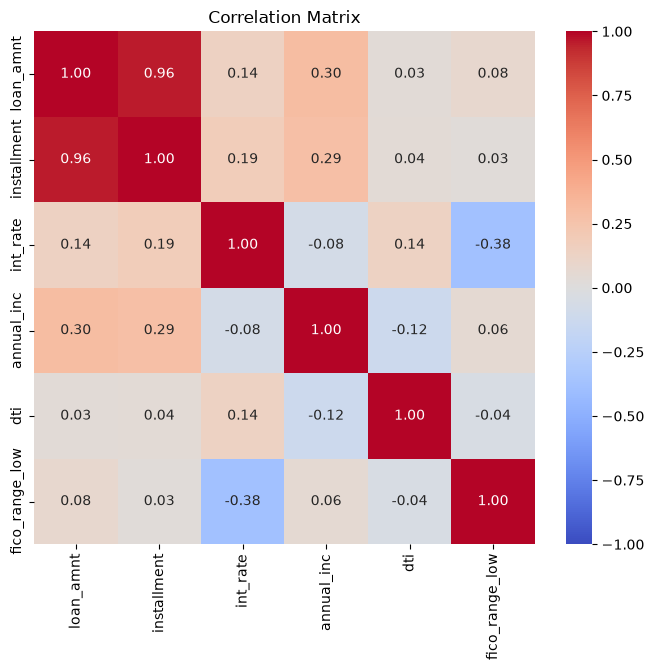

In [5]:
heatmap_columns = ["loan_amnt", "installment", "int_rate", "annual_inc", "dti", "fico_range_low"]
ge.plot_correlation_heatmap(correlations.loc[heatmap_columns, heatmap_columns])

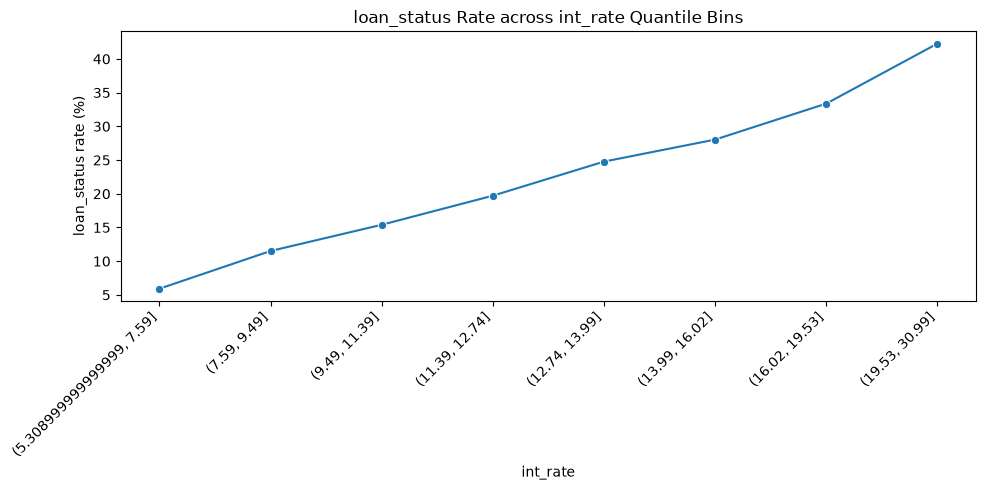

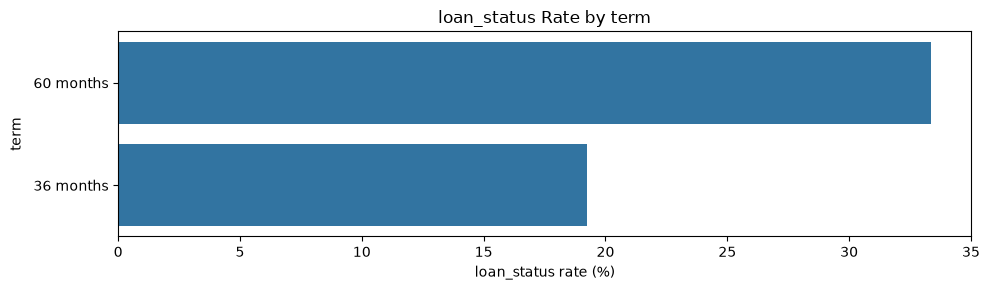

In [6]:
ge.plot_numeric_target_rate(train, "int_rate", TARGET, bins=8)
ge.plot_categorical_target_rate(train, "term", TARGET)